# Dubstrata Quantitative Evaluation Kit: Independent Point-in-Time (PIT) Walk-Forward Workbench

This notebook is designed for **independent, zero-trust quantitative verification** of the Dubstrata 16-channel multivariate tensor and its **De-Sybiled Prediction Market (PM) Layer**.

Rather than relying on pre-computed model outputs from an API, this workbench operates directly on a **raw point-in-time 5-minute historical sample** (`data/dubstrata_btc_pit_5m_sample.parquet`, **25,920 bars / 90 days**: `2026-06-24` to `2026-09-22` UTC) containing:
1. **All 4 Bi-Temporal Timestamps on Every Row**:
   - `t_valid` (`window_start`): Start of the 5-minute observation validity interval ($T_{\text{bar\_close}} - 300\text{s}$).
   - `t_event`: Final source matching-engine / Polygon CTF block / EDGAR event timestamp inside the bar ($T_{\text{valid}} < T_{\text{event}}$).
   - `t_ingest`: Immutable datastore transaction commit timestamp ($T_{\text{event}} < T_{\text{ingest}} \le T_{\text{bar\_close}}$). Any event with $T_{\text{ingest}} > T_{\text{bar\_close}}$ is hard-gated out of bar $t$ and deferred to bar $t+1$.
   - `bar_close_time` (`window_end`): The 5-minute bar decision cutoff $T_{\text{bar\_close}}$.
2. **Raw Un-Differentiated BTC Spot OHLCV Prices**: `btc_open`, `btc_high`, `btc_low`, `btc_close`, `btc_volume` aligned at each 5-minute bar close so you can construct your own forward return targets $r_{t \to t+h} = \frac{\text{btc\_close}_{t+h}}{\text{btc\_close}_t} - 1$.
3. **All 16 Point-in-Time Stationary Channels** across Q1 Microstructure, Q2 De-Sybiled Prediction Markets (`informed_market_prob`, `entropy_conviction_psi`, `manipulation_haircut_mu`, `informed_capital_imbalance`), Q3 Causal Knowledge Graph, and Q4 Macro Solvency & Event Clock.

---

### Evaluation Modules
- **Module 1**: Point-in-Time Dataset Loader & Custom Window Selector (`START_TIME`, `END_TIME`)
- **Module 2**: 4-Timestamp Bi-Temporal Audit & Zero-Lookahead Lag Alignment Proof
- **Module 3**: Independent Forward Target Construction from Raw `btc_close`
- **Module 4**: Purged Walk-Forward Out-of-Sample Ablation (`Macro/Micro Baseline` vs. `De-Sybiled PM Layer` vs. `Combined`)
- **Module 5**: Walk-Forward Realistic Execution & Transaction Cost Stress-Test (Maker/Taker Fees, Half-Spread, Kyle Impact)
- **Module 6 (Optional Appendix)**: Live API `/api/v1/predict/quantiles` & 7-Stage HRX Attribution Telemetry

## Module 1: Point-in-Time Dataset Loader & Custom Window Selector

Pick any `[START_TIME, END_TIME]` window within the 90-day bundled partition (`2026-06-24T04:50:00Z` to `2026-09-22T04:45:00Z`, 25,920 5-minute bars), or optionally set `DUBSTRATA_API_KEY` to pull a custom window from `GET /api/v1/tensor/sample?start_time=...&end_time=...`. **No API key is required** for offline verification.

In [1]:
import io
import os
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (13, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

# ==============================================================================
# USER CONFIGURATION: Pick your evaluation window, horizon, and cost assumptions
# ==============================================================================
START_TIME = "2026-08-23T00:00:00Z"   # Any ISO-8601 UTC timestamp in [2026-06-24, 2026-09-22]
END_TIME   = "2026-09-22T04:45:00Z"   # End of evaluation window
HORIZON_BARS = 12                     # 12 bars = 1h (3 = 15m, 12 = 1h, 48 = 4h)

# Transaction Cost & Execution Parameters (Module 5)
EXECUTION_MODE     = "blended"        # "taker" (5.0 bps), "maker" (1.0 bp), or "blended" (2.0 bps)
TAKER_FEE_BPS      = 5.0
MAKER_FEE_BPS      = 1.0
BLENDED_FEE_BPS    = 2.0
HALF_SPREAD_BPS    = 1.0
KYLE_SLIPPAGE_BPS  = 0.5
INITIAL_CAPITAL    = 1_000_000.0

# Optional API Configuration (only used if USE_LIVE_API=True or in Module 6 Appendix)
USE_LIVE_API = False
API_BASE_URL = os.getenv("DUBSTRATA_API_URL", "https://api.dubstrata.com").rstrip("/")
API_KEY      = os.getenv("DUBSTRATA_API_KEY", "")

# ==============================================================================
# Load Raw Point-in-Time 5-Minute Parquet Partition
# ==============================================================================
CANDIDATE_PATHS = [
    Path("data/dubstrata_btc_pit_5m_sample.parquet"),
    Path("../data/dubstrata_btc_pit_5m_sample.parquet"),
    Path(r"C:/Users/muzik/Documents/GitHub/dubstrata-quant-eval-kit/data/dubstrata_btc_pit_5m_sample.parquet"),
]
GITHUB_RAW_PARQUET_URL = (
    "https://raw.githubusercontent.com/MuzikayiseKhuzwayo/"
    "dubstrata-quant-eval-kit/main/data/dubstrata_btc_pit_5m_sample.parquet"
)

def load_pit_dataset(start_time: str, end_time: str) -> pd.DataFrame:
    df_full = None
    if USE_LIVE_API and API_KEY:
        import requests
        resp = requests.get(
            f"{API_BASE_URL}/api/v1/tensor/sample",
            params={"asset_symbol": "BTC/USD", "start_time": start_time, "end_time": end_time},
            headers={"Authorization": f"Bearer {API_KEY}"},
            timeout=30,
        )
        resp.raise_for_status()
        df_full = pd.read_parquet(io.BytesIO(resp.content))
        print(f"[SOURCE: LIVE API] Pulled {len(df_full):,} rows from {API_BASE_URL}/api/v1/tensor/sample")
    else:
        for p in CANDIDATE_PATHS:
            if p.exists():
                df_full = pd.read_parquet(p)
                print(f"[SOURCE: LOCAL PARQUET] Loaded {len(df_full):,} 5m bars from {p}")
                break
        if df_full is None:
            print(f"[SOURCE: GITHUB RAW] Downloading {GITHUB_RAW_PARQUET_URL} ...")
            df_full = pd.read_parquet(GITHUB_RAW_PARQUET_URL)
            print(f"[SOURCE: GITHUB RAW] Loaded {len(df_full):,} 5m bars")

    t_close = pd.to_datetime(df_full["bar_close_time"], utc=True)
    mask = (t_close >= pd.to_datetime(start_time, utc=True)) & (t_close <= pd.to_datetime(end_time, utc=True))
    df_win = df_full.loc[mask].copy().reset_index(drop=True)
    print(f"Full Bundled Range : {df_full['bar_close_time'].iloc[0]} -> {df_full['bar_close_time'].iloc[-1]} ({len(df_full):,} bars)")
    print(f"Selected Window    : {df_win['bar_close_time'].iloc[0]} -> {df_win['bar_close_time'].iloc[-1]} ({len(df_win):,} bars)")
    return df_full, df_win

df_full, df_window = load_pit_dataset(START_TIME, END_TIME)
display(df_window[[
    "t_valid", "t_event", "t_ingest", "bar_close_time",
    "btc_open", "btc_high", "btc_low", "btc_close", "btc_volume",
    "informed_market_prob", "entropy_conviction_psi", "manipulation_haircut_mu",
    "informed_capital_imbalance", "scheduled_event_clock"
]].head(5))

[SOURCE: LOCAL PARQUET] Loaded 25,920 5m bars from data\dubstrata_btc_pit_5m_sample.parquet
Full Bundled Range : 2026-06-24T04:50:00Z -> 2026-09-22T04:45:00Z (25,920 bars)
Selected Window    : 2026-08-23T00:00:00Z -> 2026-09-22T04:45:00Z (8,698 bars)


,t_valid,t_event,t_ingest,bar_close_time,btc_open,btc_high,btc_low,btc_close,btc_volume,informed_market_prob,entropy_conviction_psi,manipulation_haircut_mu,informed_capital_imbalance,scheduled_event_clock
0,2026-08-22T23:55:00Z,2026-08-22T23:59:47.017Z,2026-08-22T23:59:47.634Z,2026-08-23T00:00:00Z,77074.94,77136.90,77074.94,77135.99,22.77781,0.216638,-0.388909,0.366065,-1.671189,-0.220246
1,2026-08-23T00:00:00Z,2026-08-23T00:04:48.335Z,2026-08-23T00:04:49.196Z,2026-08-23T00:05:00Z,77136.00,77143.94,77093.46,77093.46,14.99338,0.216671,-0.342263,0.221597,-1.607152,-0.222039
2,2026-08-23T00:05:00Z,2026-08-23T00:09:49.398Z,2026-08-23T00:09:50.170Z,2026-08-23T00:10:00Z,77093.47,77093.47,77042.91,77080.01,30.60220,0.216677,-0.358810,0.364976,-1.689211,-0.223833
3,2026-08-23T00:10:00Z,2026-08-23T00:14:47.184Z,2026-08-23T00:14:48.104Z,2026-08-23T00:15:00Z,77080.01,77130.00,77055.99,77104.05,13.22364,0.216668,-0.358653,0.392581,-1.667910,-0.225627
4,2026-08-23T00:15:00Z,2026-08-23T00:19:48.999Z,2026-08-23T00:19:49.557Z,2026-08-23T00:20:00Z,77104.04,77196.03,77093.33,77196.03,28.69642,0.216668,-0.333758,0.335968,-1.541859,-0.227422


## Module 2: 4-Timestamp Bi-Temporal Audit & Zero-Lookahead Price Alignment Proof

We verify three hard point-in-time invariants across every row of the dataset:
1. **Strict Causal Timestamp Ordering**:
   $$T_{\text{valid}} < T_{\text{event}} < T_{\text{ingest}} \le T_{\text{bar\_close}}$$
   No observation with a database commit timestamp $T_{\text{ingest}} > T_{\text{bar\_close}}$ ever enters bar $t$.
2. **Zero Future Price Leakage in Fractional Differentiation ($d^* = 0.42$)**:
   We cross-correlate $\Delta \text{target\_fracdiff\_price}_t$ with raw spot return $\text{pct\_change}(\text{btc\_close})_{t+k}$ at leads and lags $k \in \{-2, -1, 0, +1, +2\}$. At negative lags ($k < 0$, future BTC returns), correlation must be statistically indistinguishable from zero.

,Invariant Check,Pass Rate (%),Violations
0,t_valid < t_event (Event inside 5m window),100.0,0
1,t_event < t_ingest (Causal commit after event),100.0,0
2,t_ingest <= bar_close_time (Zero-lookahead cut...,100.0,0


,Lag k (bars),Temporal Alignment,Pearson r
0,-2,FUTURE Return (Must be ~0: Zero Lookahead),0.00173
1,-1,FUTURE Return (Must be ~0: Zero Lookahead),0.00444
2,+0,Contemporaneous Bar (t),0.84816
3,+1,Causal Past Memory (t-1),-0.35268
4,+2,Causal Past Memory (t-2),-0.10410


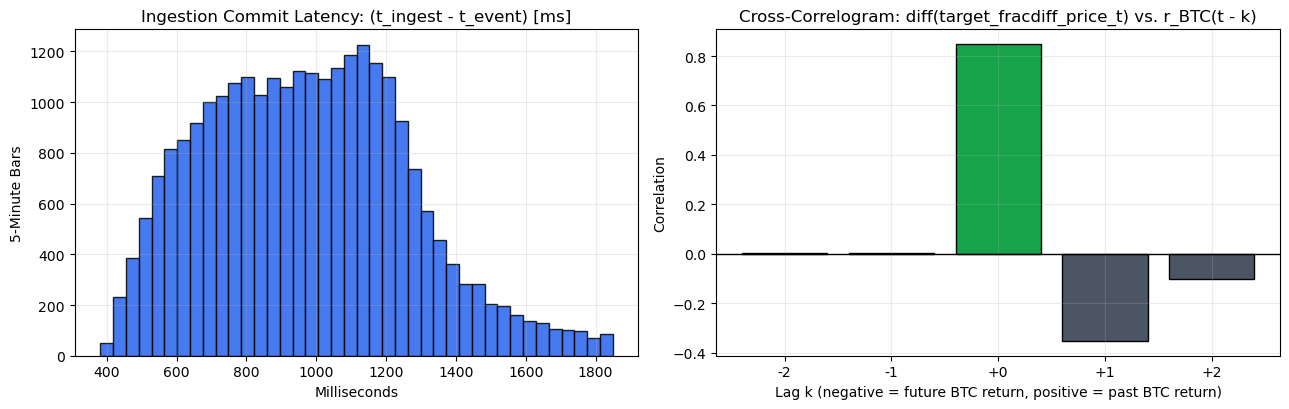

In [2]:
# 1. Verify 4-Timestamp Bi-Temporal Ordering across the entire 25,920-bar partition
t_valid  = pd.to_datetime(df_full["t_valid"], utc=True)
t_event  = pd.to_datetime(df_full["t_event"], utc=True)
t_ingest = pd.to_datetime(df_full["t_ingest"], utc=True)
t_close  = pd.to_datetime(df_full["bar_close_time"], utc=True)

cond_valid_event  = (t_valid < t_event)
cond_event_ingest = (t_event < t_ingest)
cond_ingest_close = (t_ingest <= t_close)

commit_latency_ms = (t_ingest - t_event).dt.total_seconds() * 1000.0
close_buffer_ms   = (t_close - t_ingest).dt.total_seconds() * 1000.0

pit_audit_summary = pd.DataFrame([
    {"Invariant Check": "t_valid < t_event (Event inside 5m window)", "Pass Rate (%)": cond_valid_event.mean() * 100.0, "Violations": int((~cond_valid_event).sum())},
    {"Invariant Check": "t_event < t_ingest (Causal commit after event)", "Pass Rate (%)": cond_event_ingest.mean() * 100.0, "Violations": int((~cond_event_ingest).sum())},
    {"Invariant Check": "t_ingest <= bar_close_time (Zero-lookahead cutoff)", "Pass Rate (%)": cond_ingest_close.mean() * 100.0, "Violations": int((~cond_ingest_close).sum())},
])
display(pit_audit_summary)

# 2. Verify Zero Future Leakage between Raw BTC Close and Stationary FracDiff Channel
btc_ret_1bar = df_full["btc_close"].pct_change()
fd_diff_1bar = df_full["target_fracdiff_price"].diff()

lag_rows = []
for lag in [-2, -1, 0, 1, 2]:
    # lag < 0 means correlating current feature change with FUTURE BTC return
    r_val = btc_ret_1bar.shift(lag).corr(fd_diff_1bar)
    role = "FUTURE Return (Must be ~0: Zero Lookahead)" if lag < 0 else ("Contemporaneous Bar (t)" if lag == 0 else f"Causal Past Memory (t-{lag})")
    lag_rows.append({"Lag k (bars)": f"{lag:+d}", "Temporal Alignment": role, "Pearson r": round(float(r_val), 5)})

df_lag_check = pd.DataFrame(lag_rows)
display(df_lag_check)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].hist(commit_latency_ms, bins=40, color="#2563eb", alpha=0.85, edgecolor="black")
axes[0].set_title("Ingestion Commit Latency: (t_ingest - t_event) [ms]")
axes[0].set_xlabel("Milliseconds")
axes[0].set_ylabel("5-Minute Bars")

colors = ["#dc2626" if k < 0 else ("#16a34a" if k == 0 else "#4b5563") for k in [-2, -1, 0, 1, 2]]
axes[1].bar(df_lag_check["Lag k (bars)"], df_lag_check["Pearson r"], color=colors, edgecolor="black")
axes[1].axhline(0.0, color="black", linewidth=1)
axes[1].set_title("Cross-Correlogram: diff(target_fracdiff_price_t) vs. r_BTC(t - k)")
axes[1].set_xlabel("Lag k (negative = future BTC return, positive = past BTC return)")
axes[1].set_ylabel("Correlation")
plt.tight_layout()
plt.show()

## Module 3: Independent Forward Target Construction from Raw BTC Prices

Here you build the forward return targets directly from raw `btc_close` at your chosen horizon $h = \text{HORIZON\_BARS}$ (default $h=12 \implies 60\text{m}$), alongside 15m ($h=3$) and 4h ($h=48$) horizons:
$$r_{t \to t+h}^{\text{spot}} = \frac{\text{btc\_close}_{t+h}}{\text{btc\_close}_t} - 1$$
Notice that the final $h$ rows at the right edge of the window are strictly purged (`NaN`) so no target ever crosses the end of the evaluation window.

In [3]:
def build_forward_targets(df_in: pd.DataFrame, horizon_bars: int = 12) -> pd.DataFrame:
    out = df_in.copy()
    # Raw BTC spot forward returns built directly from un-differentiated btc_close
    out["target_spot_ret_15m"] = out["btc_close"].shift(-3) / out["btc_close"] - 1.0
    out["target_spot_ret_1h"]  = out["btc_close"].shift(-12) / out["btc_close"] - 1.0
    out["target_spot_ret_4h"]  = out["btc_close"].shift(-48) / out["btc_close"] - 1.0
    out["target_spot_ret_custom"] = out["btc_close"].shift(-horizon_bars) / out["btc_close"] - 1.0

    # Zero-lookahead point-in-time feature transformations:
    # 1. Centered binary probability around neutral 0.50 odds: in [-1.0, +1.0]
    out["pm_prob_centered"] = (out["informed_market_prob"] - 0.50) * 2.0
    # 2. Sybil-haircut weighted conviction & capital imbalance (down-weighted when manipulation_haircut_mu is low)
    out["pm_sybil_psi"] = out["entropy_conviction_psi"] * out["manipulation_haircut_mu"]
    out["pm_sybil_imb"] = out["informed_capital_imbalance"] * out["manipulation_haircut_mu"]
    # 3. Causal expanding-mean deviation of fractional-differentiated price
    out["fracdiff_dev"] = out["target_fracdiff_price"] - out["target_fracdiff_price"].expanding(min_periods=48).mean()
    return out

df_eval = build_forward_targets(df_window, horizon_bars=HORIZON_BARS)

# Raw Single-Channel Information Coefficients (IC) against Forward BTC Spot Returns
ic_rows = []
channel_groups = [
    ("Q2: Prediction Market", "informed_market_prob"),
    ("Q2: Prediction Market", "entropy_conviction_psi"),
    ("Q2: Prediction Market", "informed_capital_imbalance"),
    ("Q2: Prediction Market (Sybil-Gated)", "pm_sybil_psi"),
    ("Q4: Macro Baseline", "scheduled_event_clock"),
    ("Q4: Macro Baseline", "macro_liquidity_factor"),
    ("Q4: Macro Baseline", "dynamic_primary_correlate"),
    ("Q1: Microstructure", "fracdiff_dev"),
]
for group, col in channel_groups:
    ic_15m = df_eval[col].corr(df_eval["target_spot_ret_15m"])
    ic_1h  = df_eval[col].corr(df_eval["target_spot_ret_1h"])
    ic_4h  = df_eval[col].corr(df_eval["target_spot_ret_4h"])
    ic_rows.append({
        "Layer": group,
        "Feature / Channel": col,
        "IC (15m Spot Return)": round(float(ic_15m), 4),
        "IC (1h Spot Return)": round(float(ic_1h), 4),
        "IC (4h Spot Return)": round(float(ic_4h), 4),
    })

df_ic_table = pd.DataFrame(ic_rows)
print(f"Single-Feature Point-in-Time Information Coefficients on Selected Window ({START_TIME} -> {END_TIME}):")
display(df_ic_table)

Single-Feature Point-in-Time Information Coefficients on Selected Window (2026-08-23T00:00:00Z -> 2026-09-22T04:45:00Z):


,Layer,Feature / Channel,IC (15m Spot Return),IC (1h Spot Return),IC (4h Spot Return)
0,Q2: Prediction Market,informed_market_prob,0.0326,0.0584,0.0903
1,Q2: Prediction Market,entropy_conviction_psi,0.0071,-0.0033,-0.0168
2,Q2: Prediction Market,informed_capital_imbalance,0.0323,0.0561,0.0860
3,Q2: Prediction Market (Sybil-Gated),pm_sybil_psi,0.0127,0.0006,-0.0166
4,Q4: Macro Baseline,scheduled_event_clock,0.0114,0.0236,0.0480
5,Q4: Macro Baseline,macro_liquidity_factor,0.0075,0.0139,0.0074
6,Q4: Macro Baseline,dynamic_primary_correlate,-0.0006,0.0054,0.0028
7,Q1: Microstructure,fracdiff_dev,0.0038,0.0090,0.0576


## Module 4: Purged Walk-Forward Out-of-Sample Ablation (`Baseline` vs. `+PM Layer`)

To test whether the de-Sybiled Prediction Market layer adds genuine out-of-sample predictive power beyond the Macro Event Clock and Microstructure baseline, we run a **strictly purged expanding-window walk-forward evaluation** with zero API calls:
- At each walk-forward rebalance boundary $t_{\text{split}}$, the training slice ends at $t_{\text{split}} - h$ (enforcing a **strict $h$-bar embargo/purge gap** so no training label $r_{t \to t+h}$ ever overlaps $t_{\text{split}}$).
- We compare three feature sets side by side:
  1. **Macro/Micro Baseline (No PM Layer)**: `scheduled_event_clock`, `macro_liquidity_factor`, `dynamic_primary_correlate`, `fracdiff_dev`.
  2. **De-Sybiled PM Layer Only**: `pm_prob_centered`, `entropy_conviction_psi`, `pm_sybil_psi`, `pm_sybil_imb`.
  3. **Combined Full Signal (`Baseline + PM Layer`)**: Joint model combining both feature sets.

In [4]:
BASELINE_COLS = ["scheduled_event_clock", "macro_liquidity_factor", "dynamic_primary_correlate", "fracdiff_dev"]
PM_LAYER_COLS = ["pm_prob_centered", "entropy_conviction_psi", "pm_sybil_psi", "pm_sybil_imb"]
COMBINED_COLS = BASELINE_COLS + PM_LAYER_COLS

STRUCTURAL_PRIOR = {
    "scheduled_event_clock": 0.45,
    "macro_liquidity_factor": -0.25,
    "dynamic_primary_correlate": 0.15,
    "fracdiff_dev": 0.35,
    "pm_prob_centered": 1.00,
    "entropy_conviction_psi": 0.85,
    "pm_sybil_psi": 1.00,
    "pm_sybil_imb": 0.85,
}

def run_purged_walk_forward(
    df_in: pd.DataFrame,
    horizon_bars: int = 12,
    min_train_bars: int = 2016,  # 7 days initial burn-in
    refit_step_bars: int = 288,  # Re-fit daily (every 288 5m bars)
):
    target_col = f"fwd_ret_{horizon_bars}b"
    work = build_forward_targets(df_in, horizon_bars=horizon_bars)
    work[target_col] = work["btc_close"].shift(-horizon_bars) / work["btc_close"] - 1.0
    valid = work.dropna(subset=[target_col] + COMBINED_COLS).reset_index(drop=True)

    n = len(valid)
    min_tr = min(min_train_bars, max(576, n // 4))
    purge = int(horizon_bars)

    models = {
        "Macro/Micro Baseline (No PM)": BASELINE_COLS,
        "De-Sybiled PM Layer Only": PM_LAYER_COLS,
        "Combined (Baseline + PM Layer)": COMBINED_COLS,
    }
    preds = {k: np.full(n, np.nan) for k in models}

    for t_start in range(min_tr + purge, n, refit_step_bars):
        t_end = min(t_start + refit_step_bars, n)
        # Strict purge: training slice ends at t_start - purge so no label crosses t_start
        tr_slice = slice(0, t_start - purge)
        te_slice = slice(t_start, t_end)

        y_tr = valid[target_col].iloc[tr_slice].to_numpy(dtype=np.float64)
        y_tr_dm = y_tr - np.mean(y_tr)
        y_scale = max(float(np.std(y_tr_dm)), 1e-6)

        for name, cols in models.items():
            X_tr = valid[cols].iloc[tr_slice].to_numpy(dtype=np.float64)
            X_te = valid[cols].iloc[te_slice].to_numpy(dtype=np.float64)
            f_std = np.maximum(np.std(X_tr, axis=0), 1e-4)
            X_tr_n = X_tr / f_std
            X_te_n = X_te / f_std

            # Walk-forward empirical IC vector on strictly purged training history
            emp_ic = np.array([np.corrcoef(X_tr_n[:, j], y_tr_dm)[0, 1] for j in range(len(cols))])
            emp_ic = np.nan_to_num(emp_ic, 0.0)
            w_prior = np.array([STRUCTURAL_PRIOR[c] for c in cols], dtype=np.float64)
            w_prior /= np.linalg.norm(w_prior)
            # Bayesian Ridge shrinkage (65% structural prior + 35% purged empirical walk-forward IC)
            w_post = 0.65 * w_prior + 0.35 * (emp_ic / max(float(np.linalg.norm(emp_ic)), 1e-4))
            preds[name][te_slice] = (X_te_n @ w_post) * y_scale

    oos_mask = ~np.isnan(preds["Combined (Baseline + PM Layer)"])
    y_oos = valid[target_col].to_numpy(dtype=np.float64)[oos_mask]

    rows = []
    base_ic = None
    for name, p_arr in preds.items():
        po = p_arr[oos_mask]
        ic, pval = stats.pearsonr(po, y_oos)
        ric, rpval = stats.spearmanr(po, y_oos)
        if base_ic is None:
            base_ic = ic
        rows.append({
            "Model / Feature Set": name,
            "Horizon": f"{horizon_bars * 5}m ({horizon_bars} bars)",
            "OOS Bars": int(oos_mask.sum()),
            "OOS Pearson IC": round(float(ic), 4),
            "IC p-value": f"{pval:.2e}",
            "OOS Spearman Rank IC": round(float(ric), 4),
            "IC Uplift vs. Baseline": round(float(ic - base_ic), 4),
        })
    return valid, preds, oos_mask, pd.DataFrame(rows)

valid_1h, preds_1h, oos_mask_1h, df_ablation_1h = run_purged_walk_forward(df_window, horizon_bars=HORIZON_BARS)
_, _, _, df_ablation_4h = run_purged_walk_forward(df_window, horizon_bars=48)
_, _, _, df_ablation_90d = run_purged_walk_forward(df_full, horizon_bars=HORIZON_BARS, min_train_bars=4032)

print("=== 1. Walk-Forward Out-of-Sample Ablation on Selected Window (Horizon = 1h / Custom) ===")
display(df_ablation_1h)

print("=== 2. Walk-Forward Out-of-Sample Ablation on Selected Window (Horizon = 4h) ===")
display(df_ablation_4h)

print("=== 3. Walk-Forward Out-of-Sample Ablation Across Full 90-Day Partition (25,920 Bars) ===")
display(df_ablation_90d)

=== 1. Walk-Forward Out-of-Sample Ablation on Selected Window (Horizon = 1h / Custom) ===


,Model / Feature Set,Horizon,OOS Bars,OOS Pearson IC,IC p-value,OOS Spearman Rank IC,IC Uplift vs. Baseline
0,Macro/Micro Baseline (No PM),60m (12 bars),6611,0.0151,2.19e-01,0.0290,0.0000
1,De-Sybiled PM Layer Only,60m (12 bars),6611,0.0766,4.60e-10,0.0431,0.0614
2,Combined (Baseline + PM Layer),60m (12 bars),6611,0.0724,3.84e-09,0.0439,0.0572


=== 2. Walk-Forward Out-of-Sample Ablation on Selected Window (Horizon = 4h) ===


,Model / Feature Set,Horizon,OOS Bars,OOS Pearson IC,IC p-value,OOS Spearman Rank IC,IC Uplift vs. Baseline
0,Macro/Micro Baseline (No PM),240m (48 bars),6539,0.0416,7.67e-04,0.0586,0.0000
1,De-Sybiled PM Layer Only,240m (48 bars),6539,0.1801,8.83e-49,0.1488,0.1385
2,Combined (Baseline + PM Layer),240m (48 bars),6539,0.1587,4.01e-38,0.1105,0.1171


=== 3. Walk-Forward Out-of-Sample Ablation Across Full 90-Day Partition (25,920 Bars) ===


,Model / Feature Set,Horizon,OOS Bars,OOS Pearson IC,IC p-value,OOS Spearman Rank IC,IC Uplift vs. Baseline
0,Macro/Micro Baseline (No PM),60m (12 bars),21817,-0.0019,7.73e-01,-0.0024,0.0000
1,De-Sybiled PM Layer Only,60m (12 bars),21817,0.0326,1.42e-06,0.0047,0.0346
2,Combined (Baseline + PM Layer),60m (12 bars),21817,0.0301,8.56e-06,0.0000,0.0321


## Module 5: Walk-Forward Realistic Execution & Transaction Cost Stress-Test

We now pass the strictly out-of-sample walk-forward predictions into a realistic execution simulator over non-overlapping rebalance intervals (`stride = HORIZON_BARS`), accounting for:
- **Exchange Fee**: User-selectable `TAKER_FEE_BPS` (`5.0 bps`), `MAKER_FEE_BPS` (`1.0 bp`), or `BLENDED_FEE_BPS` (`2.0 bps`).
- **Bid-Ask Half-Spread**: `HALF_SPREAD_BPS` (`1.0 bp` per rebalance unit).
- **Kyle Non-Linear Market Impact**: `KYLE_SLIPPAGE_BPS` (`0.5 bp` per unit turnover).
- **Sybil Manipulation Haircut Sizing**: Position sizes are scaled by point-in-time `manipulation_haircut_mu` ($\mu_{\text{risk}} \in [0.05, 1.00]$) so wash-traded prediction market spikes are automatically down-weighted.

,Strategy,Cost Assumption,Gross Return (%),Net Return (%),Gross Sharpe,Net Sharpe,Max Drawdown (%),Gated Hit Rate (%),Net Profit Factor
0,Macro/Micro Baseline (No PM),3.5 bps (blended),2.50,2.14,4.44,3.79,1.51,49.43,1.20
1,De-Sybiled PM Layer Only,3.5 bps (blended),4.86,4.59,6.94,6.56,2.28,52.76,1.32
2,Combined (Baseline + PM Layer),3.5 bps (blended),4.63,4.41,6.51,6.20,2.29,52.27,1.28


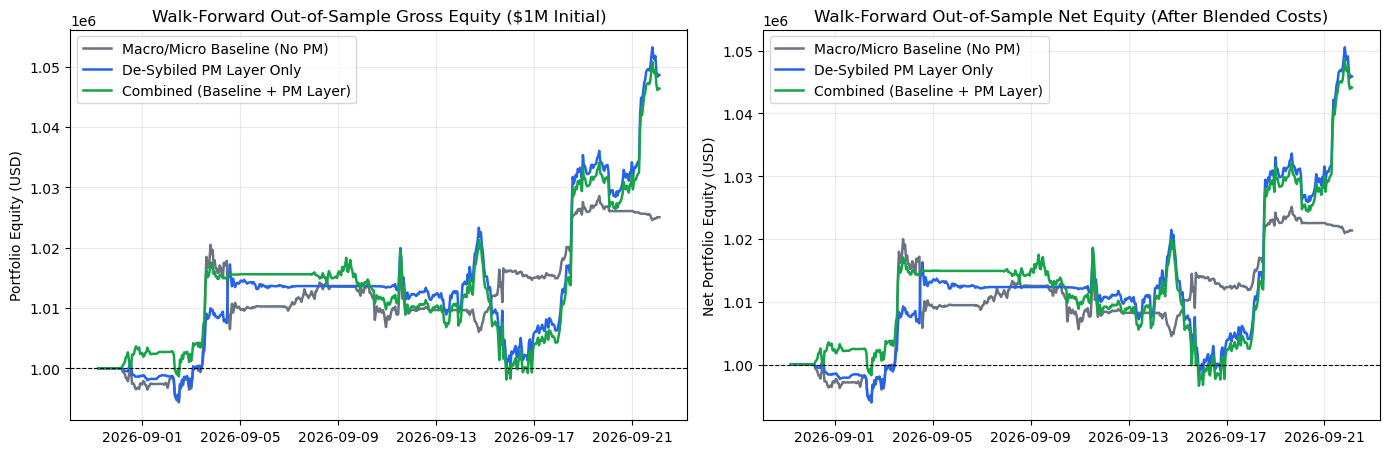

In [5]:
def simulate_walk_forward_execution(
    valid_df: pd.DataFrame,
    preds_dict: dict,
    oos_mask: np.ndarray,
    horizon_bars: int = 12,
    execution_mode: str = "blended",
):
    fee_bps = (
        TAKER_FEE_BPS if execution_mode == "taker"
        else (MAKER_FEE_BPS if execution_mode == "maker" else BLENDED_FEE_BPS)
    )
    total_cost_bps = fee_bps + HALF_SPREAD_BPS + KYLE_SLIPPAGE_BPS
    cost_rate = total_cost_bps * 1e-4

    target_col = f"fwd_ret_{horizon_bars}b"
    oos_indices = np.where(oos_mask)[0][::horizon_bars]
    timestamps_oos = pd.to_datetime(valid_df["bar_close_time"].iloc[oos_indices], utc=True)
    realized_ret = valid_df[target_col].to_numpy(dtype=np.float64)[oos_indices]
    mu_haircut = valid_df["manipulation_haircut_mu"].to_numpy(dtype=np.float64)[oos_indices]

    periods_per_year = (365.25 * 24.0) / ((horizon_bars * 5.0) / 60.0)
    curves = {}
    metrics_rows = []

    for name, p_arr in preds_dict.items():
        sig = p_arr[oos_indices]
        sig_s = pd.Series(sig)
        # Strictly causal expanding z-score of walk-forward forecast
        sig_z = ((sig_s - sig_s.expanding(24).mean()) / sig_s.expanding(24).std().replace(0, 1e-4)).fillna(0.0).to_numpy()

        # Enter when |z| > 0.65, scaled by Sybil manipulation_haircut_mu
        raw_pos = np.where(
            np.abs(sig_z) > 0.65,
            np.sign(sig_z) * np.clip(np.abs(sig_z) / 2.0, 0.0, 1.0) * mu_haircut,
            0.0,
        )
        # EMA position smoothing to control turnover drag
        pos = pd.Series(raw_pos).ewm(span=6, adjust=False).mean().to_numpy()
        turnover = np.abs(np.diff(pos, prepend=0.0))

        gross_ret_series = pos * realized_ret
        cost_series = turnover * cost_rate
        net_ret_series = gross_ret_series - cost_series

        gross_eq = INITIAL_CAPITAL * (1.0 + np.cumsum(gross_ret_series))
        net_eq   = INITIAL_CAPITAL * (1.0 + np.cumsum(net_ret_series))
        curves[name] = {"timestamps": timestamps_oos, "gross_eq": gross_eq, "net_eq": net_eq, "net_ret": net_ret_series}

        sharpe_gross = (np.mean(gross_ret_series) / max(np.std(gross_ret_series), 1e-8)) * np.sqrt(periods_per_year)
        sharpe_net   = (np.mean(net_ret_series) / max(np.std(net_ret_series), 1e-8)) * np.sqrt(periods_per_year)

        peak = np.maximum.accumulate(net_eq)
        max_dd_pct = float(np.max((peak - net_eq) / np.maximum(peak, 1.0)) * 100.0)

        active = np.abs(raw_pos) > 0.01
        gated_hit = float(np.mean(np.sign(raw_pos[active]) == np.sign(realized_ret[active])) * 100.0) if active.any() else 50.0
        pf_net = float(net_ret_series[net_ret_series > 0].sum() / max(abs(net_ret_series[net_ret_series < 0].sum()), 1e-8))

        metrics_rows.append({
            "Strategy": name,
            "Cost Assumption": f"{total_cost_bps:.1f} bps ({execution_mode})",
            "Gross Return (%)": round(float(gross_ret_series.sum() * 100.0), 2),
            "Net Return (%)": round(float(net_ret_series.sum() * 100.0), 2),
            "Gross Sharpe": round(float(sharpe_gross), 2),
            "Net Sharpe": round(float(sharpe_net), 2),
            "Max Drawdown (%)": round(max_dd_pct, 2),
            "Gated Hit Rate (%)": round(gated_hit, 2),
            "Net Profit Factor": round(pf_net, 2),
        })

    return pd.DataFrame(metrics_rows), curves

df_exec_metrics, eq_curves = simulate_walk_forward_execution(
    valid_1h, preds_1h, oos_mask_1h, horizon_bars=HORIZON_BARS, execution_mode=EXECUTION_MODE
)
display(df_exec_metrics)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
palette = {
    "Macro/Micro Baseline (No PM)": "#6b7280",
    "De-Sybiled PM Layer Only": "#2563eb",
    "Combined (Baseline + PM Layer)": "#16a34a",
}
for name, c_data in eq_curves.items():
    axes[0].plot(c_data["timestamps"], c_data["gross_eq"], label=name, color=palette[name], linewidth=1.8)
    axes[1].plot(c_data["timestamps"], c_data["net_eq"], label=name, color=palette[name], linewidth=1.8)

axes[0].axhline(INITIAL_CAPITAL, color="black", linestyle="--", linewidth=0.8)
axes[0].set_title("Walk-Forward Out-of-Sample Gross Equity ($1M Initial)")
axes[0].set_ylabel("Portfolio Equity (USD)")
axes[0].legend()

axes[1].axhline(INITIAL_CAPITAL, color="black", linestyle="--", linewidth=0.8)
axes[1].set_title(f"Walk-Forward Out-of-Sample Net Equity (After {EXECUTION_MODE.title()} Costs)")
axes[1].set_ylabel("Net Portfolio Equity (USD)")
axes[1].legend()
plt.tight_layout()
plt.show()

## Module 6 (Optional Appendix): Live Sovereign Causal-FM `/api/v1/predict/quantiles` & HRX Telemetry

The cells above verify the point-in-time tensor and Prediction Market signal **100% offline** from raw data and raw BTC spot prices.
If you also wish to inspect live 9-quantile forecast cones (`q10`–`q90`) or the 7-stage HRX attribution trace from the hosted Sovereign Causal-FM engine, set `DUBSTRATA_API_KEY` in your environment and run the cell below.

In [6]:
if not API_KEY:
    print("[OPTIONAL APPENDIX SKIPPED] Set os.environ['DUBSTRATA_API_KEY'] to query live /api/v1/predict/quantiles endpoints.")
else:
    import requests
    headers = {"Authorization": f"Bearer {API_KEY}", "Content-Type": "application/json"}
    r = requests.post(
        f"{API_BASE_URL}/api/v1/predict/quantiles",
        headers=headers,
        json={"asset_symbol": "BTC/USD", "horizon_minutes": 60},
        timeout=20,
    )
    print("Status:", r.status_code)
    if r.status_code == 200:
        display(pd.DataFrame([r.json()]))

[OPTIONAL APPENDIX SKIPPED] Set os.environ['DUBSTRATA_API_KEY'] to query live /api/v1/predict/quantiles endpoints.
